# Задание 1. Предсказание годовой зарплаты по данным о вакансиях

## 0. Описание задачи

**Датасет:** [Job Listings: Open Jobs in Every Field (Daily)](https://www.kaggle.com/datasets/chandranshbinjola/job-listings), файл `jobs.csv` (71 647 строк, 22 столбца). Он обновляется каждый день, поэтому я работаю с файлом, скачанным на фиксированную дату.

**Задача (регрессия):** по характеристикам вакансии (уровень, сфера, компания, город, навыки, опыт и т. д.) предсказать годовую зарплату `pay_mid = (pay_min + pay_max) / 2` в долларах.

Классификацию я не выбирал: готовые метки (`category`, `level`, `fresher_friendly`) автор датасета вычислил по названию вакансии и опыту, и модель просто восстанавливала бы это правило (утечка целевой переменной). Зарплату же указывает работодатель, и она действительно зависит от признаков вакансии.

**О выборке.** Зарплата в USD указана только у 20% вакансий (14 437 из 71 647). После удаления дублей остаётся 12 461 вакансия из 227 компаний. Около 64% из них пришло через Greenhouse (в основном технологические компании и стартапы), пять самых частых компаний дают около 20% данных. Поэтому выводы относятся к такой выборке, а не ко всему рынку труда.

**Метод.** Основной: регрессия k ближайших соседей. Для сравнения: Ridge, случайный лес и градиентный бустинг.

## 1. Чтение данных

In [3]:
import numpy as np
import pandas as pd

# Файл jobs.csv загружен в Colab (или лежит в data/jobs.csv в репозитории)
DATA_PATH = 'jobs.csv'
raw = pd.read_csv(DATA_PATH)
print('Размер исходного файла:', raw.shape)
print('Доля пустых ячеек во всём файле: %.1f%%' % (100 * raw.isna().mean().mean()))
print(raw['pay_currency'].value_counts(dropna=False).head(6))
raw.head(3)

Размер исходного файла: (71647, 22)
Доля пустых ячеек во всём файле: 29.0%
pay_currency
NaN    56503
USD    14437
GBP      319
EUR      271
CAD       97
PLN        5
Name: count, dtype: int64


,source,company,title,url,openings,team,category,level,years_experience,employment,...,skills,pay_min,pay_max,pay_currency,posted,first_seen,closed_at,ghost_score,ghost_reasons,fresher_friendly
0,arbeitnow,0G,Enterprise Business Development,https://www.arbeitnow.com/jobs/companies/0g/re...,1,Go to Market,sales,senior,5.0,full_time,...,negotiation;procurement,NaN,NaN,NaN,2026-10-06,2026-10-07,NaN,0.0,NaN,False
1,arbeitnow,11+,Partner & Projektmanager Fußballmarketing (m/w...,https://www.arbeitnow.com/jobs/companies/11/pa...,1,Distribution Marketing,marketing,mid,NaN,NaN,...,powerpoint;crm,NaN,NaN,NaN,2026-10-01,2026-10-04,NaN,0.0,NaN,False
2,arbeitnow,1KOMMA5˚,(Junior) Process & Operations Manager - Energy...,https://www.arbeitnow.com/jobs/companies/1komm...,1,Software Development,operations,junior,NaN,NaN,...,crm,NaN,NaN,NaN,2026-10-01,2026-10-04,NaN,0.0,NaN,True


**Определяем рабочую выборку.** Оставляем вакансии, где зарплата указана в USD (так не нужно пересчитывать курсы). Убираем строки с `pay_min > pay_max`. Удаляем дубли: одна вакансия часто публикуется в нескольких городах с одинаковой вилкой.

In [4]:
data = raw[(raw['pay_currency'] == 'USD') & raw['pay_min'].notna() & raw['pay_max'].notna()].copy()
print('USD и зарплата указана:', len(data), '| компаний:', data['company'].nunique())

print('pay_min > pay_max:', (data['pay_min'] > data['pay_max']).sum())
data = data[data['pay_min'] <= data['pay_max']].copy()
data['pay_mid'] = (data['pay_min'] + data['pay_max']) / 2

n_before = len(data)
data = data.drop_duplicates(subset=['company', 'title', 'pay_min', 'pay_max']).reset_index(drop=True)
print('Удалено дублей: %d (%.1f%%), осталось: %d' % (n_before - len(data), 100 * (n_before - len(data)) / n_before, len(data)))

print(data['source'].value_counts())
print(data['company'].value_counts().head(10))

USD и зарплата указана: 14437 | компаний: 227
pay_min > pay_max: 0
Удалено дублей: 1976 (13.7%), осталось: 12461
source
greenhouse    8014
ashby         2577
lever         1831
arbeitnow       39
Name: count, dtype: int64
company
OpenAI               667
Anthropic            532
LifeStance Health    491
Shield AI            442
Databricks           415
Rocket Lab           295
Relativity           267
Waymo                266
Veeva Systems        250
Toast                240
Name: count, dtype: int64


## 2. Разбиение на обучающую и тестовую выборки

Делим 80/20 случайно с фиксированным `random_state`. Все статистики, графики, пороги и параметры предобработки считаем **только по обучающей части**. Стратификации нет, так как цель непрерывная. Случайное разбиение оставляет одни и те же компании в обеих частях; в п. 9–10 проверим, как меняется качество на новых компаниях.

In [5]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
train_df, test_df = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
print('train:', train_df.shape, '| test:', test_df.shape)

train: (9968, 23) | test: (2493, 23)


**Подготовка признаков.** Функция `prepare` только детерминированно преобразует значения (ничего не оценивает по данным), поэтому её можно применять и к train, и к test:
- `level` в порядковое число (intern < junior < mid < senior < lead < staff+ < manager+);
- `location` сворачиваем в несколько групп (в данных много вариантов написания одного города: «San Francisco», «SF Office», «Bay Area, CA...»);
- пропуски в `employment` заменяем на категорию `unknown`, в `skills` на пустую строку (навыки не найдены);
- `remote` в 0/1.

In [6]:
import re

LEVEL_ORDER = {'intern': 0, 'junior': 1, 'mid': 2, 'senior': 3, 'lead': 4, 'staff+': 5, 'manager+': 6}

def location_group(s):
    if pd.isna(s):
        return 'unknown'
    t = s.lower()
    if re.search(r'san francisco|bay area|\bsf\b|palo alto|mountain view|sunnyvale|san jose|menlo park|redwood city', t):
        return 'sf_bay'
    if re.search(r'new york|\bnyc\b|brooklyn', t):
        return 'nyc'
    if re.search(r'seattle|bellevue|redmond', t):
        return 'seattle'
    if re.search(r'austin|boston|chicago|los angeles|denver|washington|atlanta|san diego|portland', t):
        return 'other_us_hub'
    if 'remote' in t:
        return 'remote'
    return 'other'

def prepare(df):
    out = pd.DataFrame(index=df.index)
    out['openings'] = df['openings']
    out['years_experience'] = df['years_experience']
    out['ghost_score'] = df['ghost_score']
    out['level_ord'] = df['level'].map(LEVEL_ORDER)
    out['remote_int'] = df['remote'].astype(int)
    out['source'] = df['source']
    out['category'] = df['category']
    out['company'] = df['company']
    out['employment'] = df['employment'].fillna('unknown')
    out['location_group'] = df['location'].map(location_group)
    out['skills'] = df['skills'].fillna('')
    return out

print(train_df['location'].map(location_group).value_counts())
print('level, значения вне словаря:', set(train_df['level'].unique()) - set(LEVEL_ORDER))

location
other           3136
sf_bay          3072
remote          1431
nyc             1225
other_us_hub     816
seattle          286
unknown            2
Name: count, dtype: int64
level, значения вне словаря: set()


## 3. Визуализация и основные характеристики (по обучающей выборке)

                   count       mean       std   min       25%       50%  \
pay_mid           9968.0  206167.63  83470.23  47.5  148950.0  195000.0   
openings          9968.0       1.01      0.12   1.0       1.0       1.0   
years_experience  5652.0       5.98      2.95   0.0       4.0       5.0   
ghost_score       9517.0       0.23      0.55   0.0       0.0       0.0   

                       75%       max  
pay_mid           250000.0  700000.0  
openings               1.0       6.0  
years_experience       8.0      20.0  
ghost_score            0.0       4.0  
Асимметрия pay_mid: 1.01, log1p(pay_mid): -1.42


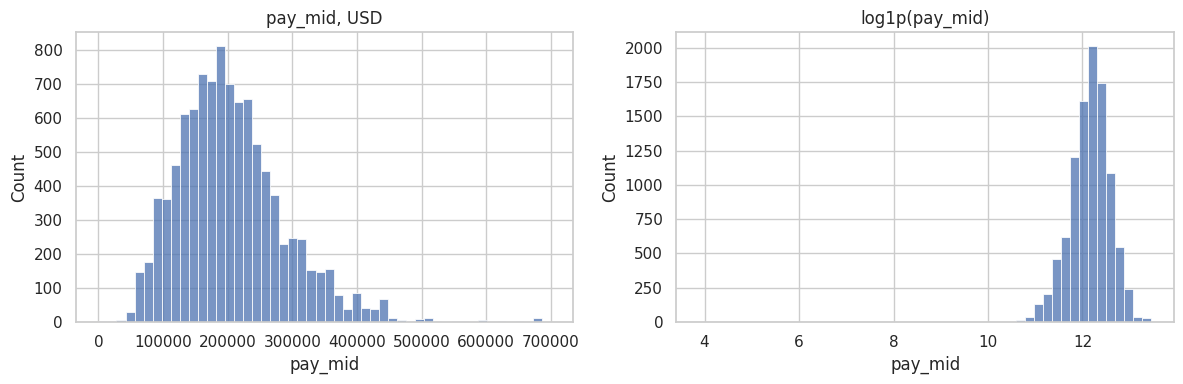

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

print(train_df[['pay_mid', 'openings', 'years_experience', 'ghost_score']].describe().T.round(2))
print('Асимметрия pay_mid: %.2f, log1p(pay_mid): %.2f' % (train_df['pay_mid'].skew(), np.log1p(train_df['pay_mid']).skew()))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_df['pay_mid'], bins=50, ax=ax[0]); ax[0].set_title('pay_mid, USD')
sns.histplot(np.log1p(train_df['pay_mid']), bins=50, ax=ax[1]); ax[1].set_title('log1p(pay_mid)')
plt.tight_layout(); plt.show()

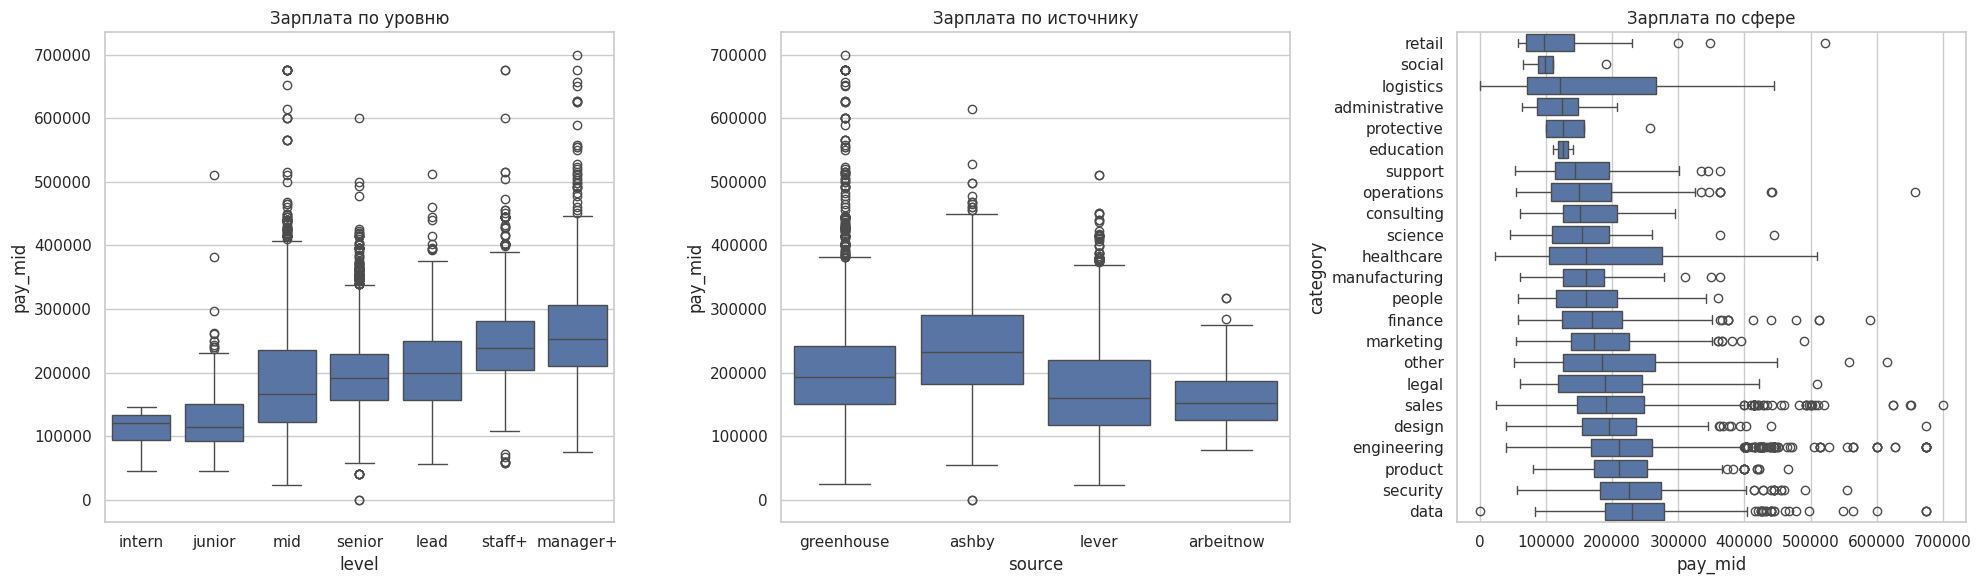

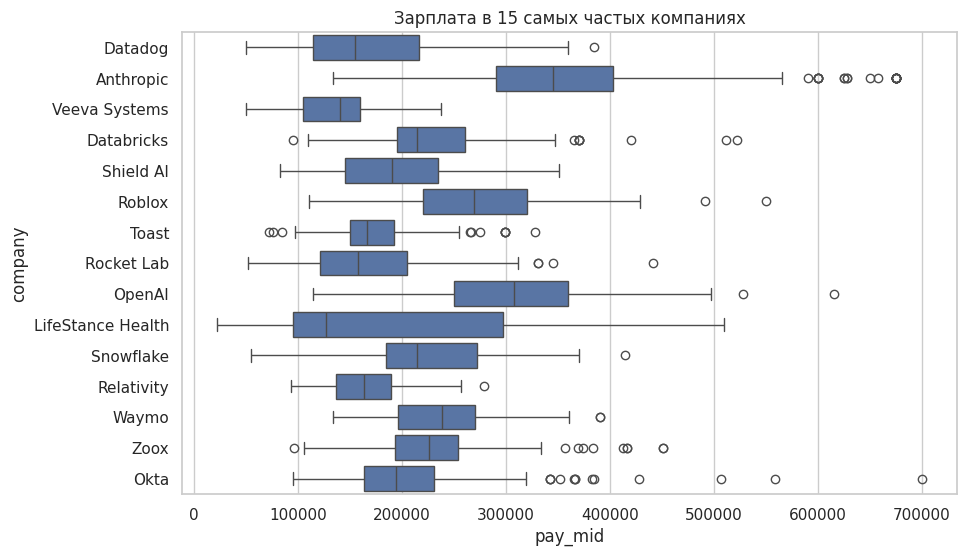

Доля вакансий пяти самых частых компаний: 20.4%


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
lvl = [l for l in LEVEL_ORDER if l in train_df['level'].unique()]
sns.boxplot(data=train_df, x='level', y='pay_mid', order=lvl, ax=ax[0]); ax[0].set_title('Зарплата по уровню')
sns.boxplot(data=train_df, x='source', y='pay_mid', ax=ax[1]); ax[1].set_title('Зарплата по источнику')
cat_order = train_df.groupby('category')['pay_mid'].median().sort_values().index
sns.boxplot(data=train_df, y='category', x='pay_mid', order=cat_order, ax=ax[2]); ax[2].set_title('Зарплата по сфере')
plt.tight_layout(); plt.show()

top = train_df['company'].value_counts().head(15).index
plt.figure(figsize=(10, 6))
sns.boxplot(data=train_df[train_df['company'].isin(top)], y='company', x='pay_mid')
plt.title('Зарплата в 15 самых частых компаниях'); plt.show()
print('Доля вакансий пяти самых частых компаний: %.1f%%' % (100 * train_df['company'].value_counts().head(5).sum() / len(train_df)))

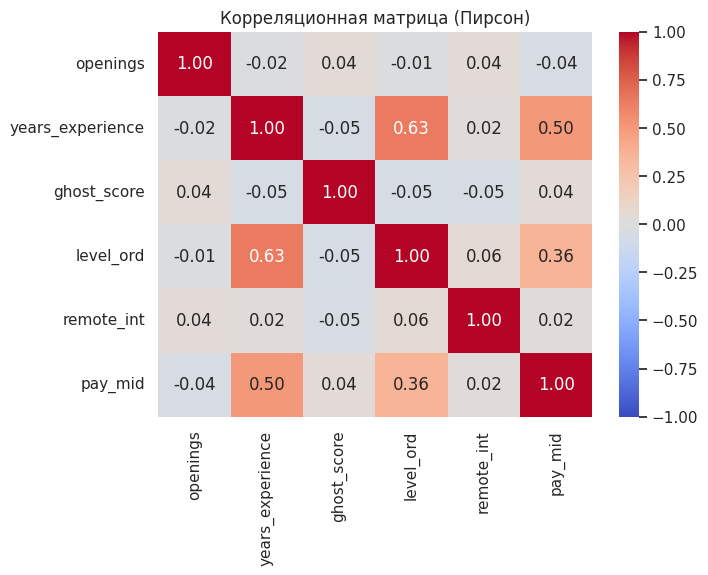

In [9]:
eda = prepare(train_df)
eda['pay_mid'] = train_df['pay_mid']
num_eda = ['openings', 'years_experience', 'ghost_score', 'level_ord', 'remote_int', 'pay_mid']
plt.figure(figsize=(7, 5))
sns.heatmap(eda[num_eda].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляционная матрица (Пирсон)'); plt.show()

**Что видно по графикам и статистикам.**

Зарплата скошена вправо: асимметрия 1.01, медиана (195 тыс.) ниже среднего (206 тыс.). После `log1p` асимметрия стала −1.42, то есть хвост «перевернулся» влево. Виноваты два аномально малых значения (47.5 и 290 $), они видны как точки у нуля на графиках. В п. 4 мы их удалим, и асимметрия логарифма станет −0.39.

Уровень вакансии связан с зарплатой монотонно, но не строго: медианы растут от \~120 тыс. у intern и junior до \~255 тыс. у manager+, при этом уровни сильно перекрываются, а senior и lead почти не различаются (\~190 и \~200 тыс.). Источник тоже влияет: у Ashby медиана выше (~230 тыс.), чем у Greenhouse (\~195 тыс.) и Lever (\~160 тыс.), но, скорее всего, источник просто отражает, какие компании им пользуются. Сфера различает слабее: у большинства сфер медианы лежат в диапазоне 120–230 тыс. и широко перекрываются (ниже всего retail, выше всего data и security). Это неудивительно, ведь сфера определена по названию.

Сильнее всего зарплата зависит от компании. Среди 15 самых частых медианы идут от ~125 тыс. (LifeStance Health) и ~140 тыс. (Veeva Systems) до ~310 тыс. у OpenAI и ~345 тыс. у Anthropic. При этом ни одна компания не доминирует: пять самых частых дают около 20% обучающей выборки.

В корреляционной матрице сильнее всего с зарплатой связан опыт (`years_experience`, r = 0.50), затем уровень (`level_ord`, 0.36). Остальные признаки (`openings`, `ghost_score`, `remote_int`) с зарплатой практически не связаны (|r| ≤ 0.04). Опыт и уровень коррелируют между собой (0.63), к этому вернёмся в п. 12. `openings` почти всегда равен 1, поэтому признак почти бесполезен, а опыт указан примерно у 57% вакансий.

## 4. Выбросы

In [10]:
def iqr_bounds(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

def iqr_share(s):
    lo, hi = iqr_bounds(s)
    s = s.dropna()
    return ((s < lo) | (s > hi)).mean()

print('Самые маленькие pay_mid:', train_df['pay_mid'].nsmallest(10).round(1).tolist())
print('Самые большие pay_mid:  ', train_df['pay_mid'].nlargest(5).round(1).tolist())
for t in [10_000, 20_000, 30_000, 40_000]:
    print('pay_mid < %6d: %.2f%%' % (t, 100 * (train_df['pay_mid'] < t).mean()))

print()
print('Доля выбросов по правилу 1.5*IQR:')
for c in ['pay_mid', 'openings', 'years_experience', 'ghost_score']:
    print('  %-17s %.1f%%' % (c, 100 * iqr_share(train_df[c])))
print('  log1p(pay_mid)    %.1f%%' % (100 * iqr_share(np.log1p(train_df['pay_mid']))))

lo, hi = iqr_bounds(train_df['pay_mid'])
print()
print('Выбросы pay_mid (> %.0f) по компаниям:' % hi)
print(train_df.loc[train_df['pay_mid'] > hi, 'company'].value_counts().head(5))

Самые маленькие pay_mid: [47.5, 290.0, 22500.0, 23996.5, 27458.0, 30514.0, 40000.0, 40000.0, 40000.0, 40000.0]
Самые большие pay_mid:   [700000.0, 675000.0, 675000.0, 675000.0, 675000.0]
pay_mid <  10000: 0.02%
pay_mid <  20000: 0.02%
pay_mid <  30000: 0.05%
pay_mid <  40000: 0.06%

Доля выбросов по правилу 1.5*IQR:
  pay_mid           2.6%
  openings          0.8%
  years_experience  1.6%
  ghost_score       17.5%
  log1p(pay_mid)    1.9%

Выбросы pay_mid (> 401575) по компаниям:
company
Anthropic            131
OpenAI                64
LifeStance Health     16
Roblox                11
Zoox                   5
Name: count, dtype: int64


**Что делаем с выбросами.**

Два значения `pay_mid` (47.5 и 290 \$) - явно не годовые зарплаты, а почасовые ставки или ошибки парсинга; именно они ломали логарифм цели. Эти две строки удаляем по фиксированному порогу 20 000 \$ (следующее значение, 22 500 \$, ещё правдоподобно для неполной занятости). Порог не подбирался по тесту, и в тесте таких строк всё равно не оказалось.

Остальные 2.6% «выбросов» это настоящие высокие зарплаты (до 700 тыс. $), около трёх четвертей которых принадлежат двум компаниям, Anthropic и OpenAI. Удалять их нельзя: мы потеряли бы информацию как раз о дорогих позициях. Поэтому просто смягчаем хвост логарифмом цели.

По `openings` (0.8%) и `years_experience` (1.6%) выбросы тоже настоящие (20 лет опыта вполне реалистично), их оставляем. Для `ghost_score` почти все значения нулевые, и любое ненулевое попадает в «выбросы» (17.5%), хотя это просто порядковый балл.

In [11]:
MIN_PAY = 20_000

def clean(df):
    return df[df['pay_mid'] >= MIN_PAY].copy()

n_tr, n_te = len(train_df), len(test_df)
train_df, test_df = clean(train_df), clean(test_df)
print('Удалено: train %d, test %d | осталось: train %d, test %d' % (n_tr - len(train_df), n_te - len(test_df), len(train_df), len(test_df)))
print('Асимметрия pay_mid: %.2f, log1p(pay_mid): %.2f' % (train_df['pay_mid'].skew(), np.log1p(train_df['pay_mid']).skew()))

Удалено: train 2, test 0 | осталось: train 9966, test 2493
Асимметрия pay_mid: 1.01, log1p(pay_mid): -0.39


## 5. Пропущенные значения

In [12]:
cols = ['years_experience', 'employment', 'skills', 'location', 'ghost_score', 'level', 'category', 'company']
miss = (train_df[cols].isna().mean() * 100).round(1).rename('% пропусков')
print(miss.to_string())

years_experience    43.3
employment          69.1
skills              14.2
location             0.0
ghost_score          4.5
level                0.0
category             0.0
company              0.0


**Решения.**
- `years_experience`: пропуск означает «опыт в тексте не указан», а не случайную потерю. Заполняем медианой **и добавляем индикатор пропуска**, чтобы модель видела сам факт отсутствия.
- `ghost_score`: небольшая доля пропусков, медиана (с индикатором).
- `employment` (около 69% пропусков), `skills`, `location`: пропуск превращаем в отдельное значение (`unknown`, пустая строка). Для `employment` это означает, что реальная информация есть лишь у ~31% вакансий, и признак почти ничего не добавит; оставляем, так как он не мешает.
- Строки с пропусками удалять не будем: пропала бы большая часть данных.
- Признаки `team`, `title`, `ghost_reasons`, `url`, `closed_at`, `posted`, `first_seen`, `pay_min`, `pay_max`, `pay_currency`, `fresher_friendly` в модель не берём: идентификатор, служебные поля краулера, даты сбора (не определяют зарплату), компоненты цели и признак, дублирующий `level`.

Медиана и индикаторы **оцениваются по train** и применяются к test.

In [13]:
from sklearn.impute import SimpleImputer

X_train, y_train = prepare(train_df), train_df['pay_mid']
X_test, y_test = prepare(test_df), test_df['pay_mid']
print('Пропуски после prepare (train):')
print(X_train.isna().sum()[lambda s: s > 0])

miss_cols = ['years_experience', 'ghost_score']
imp = SimpleImputer(strategy='median', add_indicator=True)
imp.fit(X_train[miss_cols])
imp_names = list(imp.get_feature_names_out())
print('Медианы из train:', dict(zip(miss_cols, imp.statistics_)))

def impute(X):
    X = X.copy()
    X[imp_names] = imp.transform(X[miss_cols])
    return X

X_train_i, X_test_i = impute(X_train), impute(X_test)
print('Пропусков осталось: train', X_train_i.isna().sum().sum(), '| test', X_test_i.isna().sum().sum())

Пропуски после prepare (train):
years_experience    4316
ghost_score          451
dtype: int64
Медианы из train: {'years_experience': np.float64(5.0), 'ghost_score': np.float64(0.0)}
Пропусков осталось: train 0 | test 0


In [14]:
# Сводка для таблицы заданий
work_cols = [c for c in raw.columns if c != 'url']
print('N (исходный файл):', len(raw), '| N (рабочая выборка):', len(data))
print('d (исходных признаков без url):', len(work_cols))
print('Пропуски, весь файл: %.1f%%' % (100 * raw.isna().mean().mean()))
print('Пропуски в рабочей выборке (без pay_*): %.1f%%' % (100 * data[[c for c in work_cols if not c.startswith('pay_')]].isna().mean().mean()))
print('Асимметрия цели:', round(data['pay_mid'].skew(), 2))

N (исходный файл): 71647 | N (рабочая выборка): 12461
d (исходных признаков без url): 21
Пропуски, весь файл: 29.0%
Пропуски в рабочей выборке (без pay_*): 17.2%
Асимметрия цели: 1.01


## 6. Обработка категориальных признаков

- `source`, `category`, `employment`, `location_group`, `company`: one-hot-кодирование. Значения, встречающиеся в train реже 30 раз, объединяются в одну категорию «редкие» (так 227 компаний не превращаются в десятки почти пустых столбцов, а новые компании в test попадают в «редкие»).
- `skills` (`python;aws;sql`): мультиметочный признак, кодируем 30 самых частых навыков столбцами 0/1.
- `level` уже стал порядковым числом, `remote` бинарным.

In [15]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer

cat_cols = ['source', 'category', 'employment', 'location_group', 'company']
enc = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=False)
enc.fit(X_train_i[cat_cols])

def split_skills(s):
    return [t for t in s.split(';') if t]

vec = CountVectorizer(tokenizer=split_skills, token_pattern=None, lowercase=False, binary=True, max_features=30)
vec.fit(X_train_i['skills'])

def encode(X):
    dummies = pd.DataFrame(enc.transform(X[cat_cols]), columns=enc.get_feature_names_out(), index=X.index)
    skills = pd.DataFrame(vec.transform(X['skills']).toarray(),
                          columns=['skill_' + s for s in vec.get_feature_names_out()], index=X.index)
    return pd.concat([X.drop(columns=cat_cols + ['skills']), dummies, skills], axis=1)

X_train_e, X_test_e = encode(X_train_i), encode(X_test_i)
print('Столбцов после кодирования:', X_train_e.shape[1])
for c in cat_cols:
    print('  %-15s %d столбцов' % (c, sum(n.startswith(c + '_') for n in enc.get_feature_names_out())))
print('  skills          %d столбцов' % len(vec.get_feature_names_out()))
print('Самые частые навыки в train:')
sk = X_train['skills'].str.split(';').explode()
print(sk[sk != ''].value_counts().head(10).to_string())

Столбцов после кодирования: 155
  source          4 столбцов
  category        20 столбцов
  employment      3 столбцов
  location_group  7 столбцов
  company         84 столбцов
  skills          30 столбцов
Самые частые навыки в train:
skills
python                2188
ml                    1823
sql                   1177
aws                    987
salesforce             784
talent_acquisition     764
supply_chain           679
typescript             660
project_management     654
forecasting            645


## 7. Нормализация

Нужна, потому что kNN считает евклидово расстояние: без масштабирования `years_experience` (единицы-десятки) и `level_ord` заглушили бы бинарные столбцы 0/1. Стандартизируем числовые столбцы (включая индикаторы пропусков) по train. У `openings` длинный хвост (до 6 при среднем 1.01), поэтому перед стандартизацией берём `log1p`. Бинарные 0/1 столбцы не трогаем.

Цель берём как `log1p(pay_mid)` (см. п. 3), а метрики считаем в долларах (обратное преобразование делает `TransformedTargetRegressor`).

In [16]:
from sklearn.preprocessing import StandardScaler

scale_cols = ['openings', 'years_experience', 'ghost_score', 'level_ord'] + [c for c in imp_names if c.startswith('missingindicator')]

def log_openings(X):
    X = X.copy()
    X['openings'] = np.log1p(X['openings'])
    return X

scaler = StandardScaler().fit(log_openings(X_train_e)[scale_cols])

def scale(X):
    X = log_openings(X)
    X[scale_cols] = scaler.transform(X[scale_cols])
    return X

X_train_s, X_test_s = scale(X_train_e), scale(X_test_e)
print(X_train_s[scale_cols].describe().loc[['mean', 'std']].round(2))
print('Итоговая матрица признаков:', X_train_s.shape, X_test_s.shape)

      openings  years_experience  ghost_score  level_ord  \
mean      -0.0               0.0          0.0        0.0   
std        1.0               1.0          1.0        1.0   

      missingindicator_years_experience  missingindicator_ghost_score  
mean                               -0.0                          -0.0  
std                                 1.0                           1.0  
Итоговая матрица признаков: (9966, 155) (2493, 155)


## 8. Метод: регрессия k ближайших соседей

**Выбор метода.** `KNeighborsRegressor`: базовый метод, нет предположений о форме зависимости, прогноз прост в интерпретации (средняя зарплата похожих вакансий). Минусы: чувствителен к масштабу и числу бинарных признаков, плохо работает при высокой размерности, не отбирает признаки. Поэтому в п. 10 сравниваем с другими методами. Нижняя граница качества: прогноз медианой обучающей выборки (`DummyRegressor`).

In [17]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

def evaluate(model, name, Xtr, Xte):
    row = {'model': name}
    for part, (X, y) in {'train': (Xtr, y_train), 'test': (Xte, y_test)}.items():
        p = model.predict(X)
        row[part + '_MAE'] = mean_absolute_error(y, p)
        row[part + '_RMSE'] = np.sqrt(mean_squared_error(y, p))
        row[part + '_R2'] = r2_score(y, p)
    results.append(row)
    return pd.DataFrame([row]).set_index('model').round(2)

def log_target(regressor):
    return TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)

dummy_manual = log_target(DummyRegressor(strategy='median')).fit(X_train_s, y_train)
display(evaluate(dummy_manual, 'Dummy (медиана)', X_train_s, X_test_s))

knn5 = log_target(KNeighborsRegressor(n_neighbors=5)).fit(X_train_s, y_train)
display(evaluate(knn5, 'kNN, k=5', X_train_s, X_test_s))

,train_MAE,train_RMSE,train_R2,test_MAE,test_RMSE,test_R2
model,,,,,,
Dummy (медиана),63354.7,84173.05,-0.02,63524.38,84139.49,-0.01


,train_MAE,train_RMSE,train_R2,test_MAE,test_RMSE,test_R2
model,,,,,,
"kNN, k=5",31841.28,47688.32,0.67,38699.94,55959.44,0.55


## 9. Ошибки и подбор числа соседей

Метрики: MAE (средняя абсолютная ошибка в долларах, интерпретируется напрямую), RMSE (сильнее штрафует крупные промахи), R² (доля объяснённой дисперсии).

Для подбора `k` кросс-валидацией собираем те же шаги (импутер, кодирование, масштаб) в `Pipeline`: так на каждом блоке кросс-валидации они заново оцениваются только по обучающей части блока, и информация о проверочном блоке не просачивается. Критерий подбора: MAE по 5 блокам, только на train.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import GridSearchCV, KFold

def make_preprocessor(num_cols=('years_experience', 'ghost_score', 'level_ord')):
    return ColumnTransformer([
        ('open', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                           ('sc', StandardScaler())]), ['openings']),
        ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                          ('sc', StandardScaler())]), list(num_cols)),
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=False), cat_cols),
        ('bin', 'passthrough', ['remote_int']),
        ('skills', CountVectorizer(tokenizer=split_skills, token_pattern=None, lowercase=False,
                                   binary=True, max_features=30), 'skills'),
    ], sparse_threshold=0)

def make_model(regressor, num_cols=('years_experience', 'ghost_score', 'level_ord')):
    return log_target(Pipeline([('prep', make_preprocessor(num_cols)), ('model', regressor)]))

# Проверка: Pipeline даёт то же, что ручные шаги из п. 5-7
knn5_pipe = make_model(KNeighborsRegressor(n_neighbors=5)).fit(X_train, y_train)
print('kNN k=5, test MAE: вручную %.0f | Pipeline %.0f (мелкие расхождения возможны из-за порядка столбцов и равных расстояний)' % (
    mean_absolute_error(y_test, knn5.predict(X_test_s)), mean_absolute_error(y_test, knn5_pipe.predict(X_test))))

kNN k=5, test MAE: вручную 38700 | Pipeline 38698 (мелкие расхождения возможны из-за порядка столбцов и равных расстояний)


Лучшие параметры: {'regressor__model__n_neighbors': 10, 'regressor__model__weights': 'distance'}
CV MAE: 37626 $


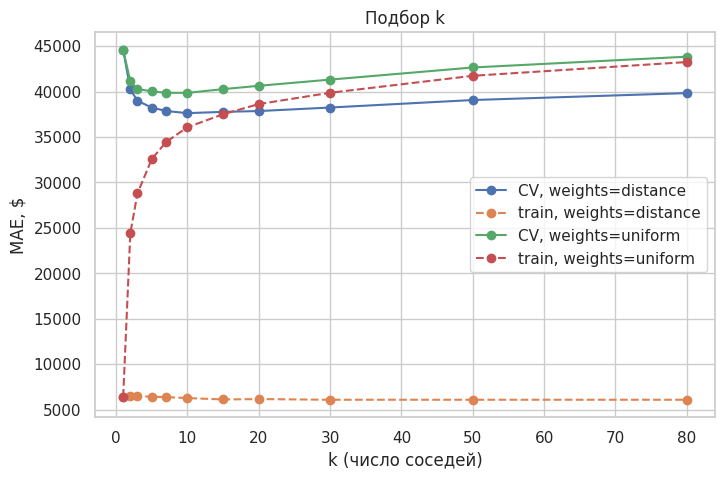

In [19]:
param_grid = {'regressor__model__n_neighbors': [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 80],
              'regressor__model__weights': ['uniform', 'distance']}
gs = GridSearchCV(make_model(KNeighborsRegressor()), param_grid,
                  cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                  scoring='neg_mean_absolute_error', return_train_score=True, n_jobs=-1)
gs.fit(X_train, y_train)
print('Лучшие параметры:', gs.best_params_)
print('CV MAE: %.0f $' % -gs.best_score_)

cvr = pd.DataFrame(gs.cv_results_)
plt.figure(figsize=(8, 5))
for w, g in cvr.groupby('param_regressor__model__weights'):
    g = g.sort_values('param_regressor__model__n_neighbors')
    k = g['param_regressor__model__n_neighbors']
    plt.plot(k, -g['mean_test_score'], 'o-', label='CV, weights=%s' % w)
    plt.plot(k, -g['mean_train_score'], 'o--', label='train, weights=%s' % w)
plt.xlabel('k (число соседей)'); plt.ylabel('MAE, $'); plt.legend(); plt.title('Подбор k'); plt.show()

,train_MAE,train_RMSE,train_R2,test_MAE,test_RMSE,test_R2
model,,,,,,
"kNN, лучший k",6586.31,24759.45,0.91,36477.98,53188.8,0.6


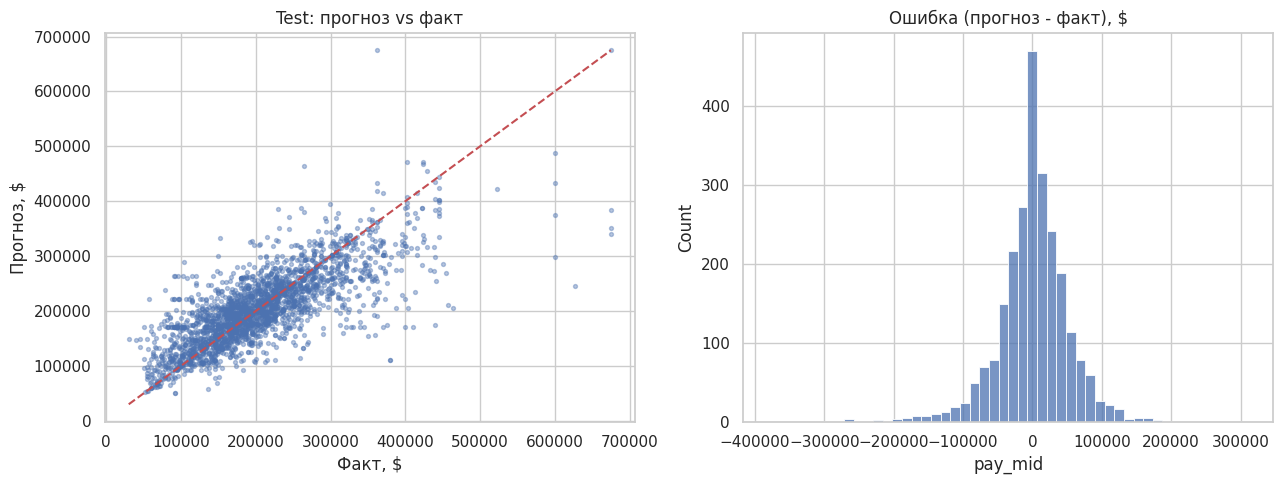

             mean  count
level                   
intern    42531.0      8
junior    24491.0     95
lead      39124.0    128
manager+  47907.0    226
mid       44375.0    799
senior    29163.0    853
staff+    31527.0    384
               abs_err  signed_err
true_quartile                     
Q1 (дёшево)    37460.0     30281.0
Q2             26752.0     12316.0
Q3             27807.0     -1840.0
Q4 (дорого)    54279.0    -41332.0


In [20]:
best_knn = gs.best_estimator_
display(evaluate(best_knn, 'kNN, лучший k', X_train, X_test))

pred = best_knn.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, pred, s=8, alpha=.4)
lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, 'r--'); ax[0].set_xlabel('Факт, $'); ax[0].set_ylabel('Прогноз, $'); ax[0].set_title('Test: прогноз vs факт')
sns.histplot(pred - y_test, bins=50, ax=ax[1]); ax[1].set_title('Ошибка (прогноз - факт), $')
plt.tight_layout(); plt.show()

err = pd.DataFrame({'level': test_df['level'], 'true_quartile': pd.qcut(y_test, 4, labels=['Q1 (дёшево)', 'Q2', 'Q3', 'Q4 (дорого)']),
                    'abs_err': (pred - y_test).abs(), 'signed_err': pred - y_test})
print(err.groupby('level')['abs_err'].agg(['mean', 'count']).round(0))
print(err.groupby('true_quartile', observed=False)[['abs_err', 'signed_err']].mean().round(0))

**Что получилось.**

1. Прогноз медианой даёт MAE около 63.5 тыс. \$ и R² около нуля. Подобранный kNN ошибается в среднем на 36.5 тыс. $ (почти вдвое меньше), R² = 0.60. Выигрыш заметный, но типичная ошибка всё равно около 19% от медианной зарплаты.
2. Про переобучение. При `weights='distance'` ошибка на train маленькая (MAE 6.6 тыс., R² 0.91), потому что каждая обучающая точка сама себе ближайший сосед, так что эти цифры качества не показывают. Честнее смотреть на `k=5` с равными весами: R² на train 0.67, на test 0.55, то есть переобучение умеренное. MAE на кросс-валидации (37.6 тыс.) близка к MAE на тесте (36.5 тыс.), поэтому оценке на тесте можно доверять.
3. Выбор k. Малые k делают модель чувствительной к шуму, большие сглаживают различия между вакансиями. Лучший компромисс по кросс-валидации: `k=10` с весами по расстоянию.
4. Где модель ошибается. Лучше всего предсказываются junior (MAE 24.5 тыс.), senior (29.2 тыс.) и staff+ (31.5 тыс.), хуже всего manager+ (47.9 тыс.) и mid (44.4 тыс.); по intern всего 8 вакансий в тесте, выводов по ним делать нельзя. Дорогие вакансии (верхний квартиль) модель в среднем занижает на 41 тыс., а дешёвые (нижний квартиль) завышает на 30 тыс. Это обычное «сжатие к среднему»: прогноз усредняет соседей и поэтому тянется к центру.

### Проверка: что будет с новыми компаниями

В данных 227 компаний, а зарплаты внутри одной компании похожи. При случайном разбиении «соседом» вакансии становится другая вакансия той же компании. Проверим на разбиении, где компании в train и test **не пересекаются**.

In [21]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import clone

all_df = pd.concat([train_df, test_df])
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE).split(all_df, groups=all_df['company']))
Xg_tr, yg_tr = prepare(all_df.iloc[tr_idx]), all_df.iloc[tr_idx]['pay_mid']
Xg_te, yg_te = prepare(all_df.iloc[te_idx]), all_df.iloc[te_idx]['pay_mid']
print('Пересечение компаний train/test:', len(set(all_df.iloc[tr_idx]['company']) & set(all_df.iloc[te_idx]['company'])))

dummy = make_model(DummyRegressor(strategy='median')).fit(X_train, y_train)
rows = []
for name, m in [('Dummy (медиана)', dummy), ('kNN, лучший k', best_knn)]:
    mg = clone(m).fit(Xg_tr, yg_tr)
    pg = mg.predict(Xg_te)
    rows.append({'model': name,
                 'MAE, случайное разбиение': mean_absolute_error(y_test, m.predict(X_test)),
                 'MAE, новые компании': mean_absolute_error(yg_te, pg),
                 'R2, новые компании': r2_score(yg_te, pg)})
display(pd.DataFrame(rows).set_index('model').round(2))

Пересечение компаний train/test: 0


,"MAE, случайное разбиение","MAE, новые компании","R2, новые компании"
model,,,
Dummy (медиана),63524.38,69644.27,-0.07
"kNN, лучший k",36477.98,52657.56,0.17


**Вывод.** На новых компаниях kNN ошибается заметно сильнее: MAE 52.7 тыс. вместо 36.5 тыс., R² падает с 0.60 до 0.17. Простая медиана тоже ухудшилась (с 63.5 до 69.6 тыс.), потому что в этом разбиении другой состав теста, но разрыв между методами сократился с 27 до 17 тыс. То есть заметная часть успеха kNN в случайном тесте это «узнавание» компании: соседями становятся другие вакансии той же компании с похожими зарплатами. Для незнакомых компаний модель всё равно лучше медианы. Одно разбиение даёт шумную оценку (в тест попало несколько десятков компаний), поэтому в п. 10 сравним все методы на пяти блоках по компаниям.

## 10. Другие методы

Сравниваем с Ridge-регрессией, случайным лесом и градиентным бустингом на той же предобработке и тех же данных (гиперпараметры по умолчанию, без настройки: цель сравнения в порядке величины, а не в победителе).

In [22]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

others = {
    'Ridge': Ridge(alpha=10),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
fitted = {}
for name, reg in others.items():
    fitted[name] = make_model(reg).fit(X_train, y_train)
    evaluate(fitted[name], name, X_train, X_test)

res = pd.DataFrame(results).drop_duplicates('model', keep='last').set_index('model').round(2)
display(res[['train_MAE', 'test_MAE', 'train_RMSE', 'test_RMSE', 'train_R2', 'test_R2']])

,train_MAE,test_MAE,train_RMSE,test_RMSE,train_R2,test_R2
model,,,,,,
Dummy (медиана),63354.70,63524.38,84173.05,84139.49,-0.02,-0.01
"kNN, k=5",31841.28,38699.94,47688.32,55959.44,0.67,0.55
"kNN, лучший k",6586.31,36477.98,24759.45,53188.80,0.91,0.60
Ridge,36964.77,37012.25,53562.77,53088.98,0.59,0.60
Random Forest,21241.36,32937.22,35678.28,48918.02,0.82,0.66
HistGradientBoosting,31183.77,33160.19,46513.99,48725.50,0.69,0.66


**Сравнение методов.** Лучше всех справляются случайный лес (MAE 32.9 тыс., R² = 0.66) и градиентный бустинг (33.2 тыс., R² = 0.66). По сравнению с kNN (36.5 тыс.) это примерно на 9–10% меньше по MAE и на 8% по RMSE (48.7–48.9 против 53.2 тыс.), то есть деревья реже сильно промахиваются. Ridge-регрессия (MAE 37.0 тыс., R² = 0.60) по качеству почти не отличается от kNN.

Деревья сами выбирают важные признаки, а в kNN каждый из 155 столбцов влияет на расстояние почти одинаково, поэтому слабые признаки (например, редкие навыки) ему мешают. Сильнее всего переобучается kNN с весами по расстоянию (R² 0.91 на train против 0.60 на тесте), у леса переобучение заметное (0.82 против 0.66), у бустинга почти нет (0.69 против 0.66).

In [23]:
# Сравнение методов на блоках по компаниям (GroupKFold) и на случайных блоках
from sklearn.model_selection import GroupKFold, cross_val_predict

X_all, y_all, groups = prepare(all_df), all_df['pay_mid'], all_df['company']
models = {'Dummy (медиана)': dummy, 'kNN, лучший k': best_knn}
models.update({n: make_model(r) for n, r in others.items()})

rows = []
for name, m in models.items():
    row = {'model': name}
    for cv_name, cv, g in [('случайные блоки', KFold(5, shuffle=True, random_state=RANDOM_STATE), None),
                           ('блоки по компаниям', GroupKFold(5), groups)]:
        p = cross_val_predict(clone(m), X_all, y_all, cv=cv, groups=g)
        row['MAE, ' + cv_name] = mean_absolute_error(y_all, p)
        row['R2, ' + cv_name] = r2_score(y_all, p)
    rows.append(row)
display(pd.DataFrame(rows).set_index('model').round(2))

,"MAE, случайные блоки","R2, случайные блоки","MAE, блоки по компаниям","R2, блоки по компаниям"
model,,,,
Dummy (медиана),63402.15,-0.02,63763.45,-0.03
"kNN, лучший k",36381.84,0.59,54393.23,0.15
Ridge,37424.90,0.58,55836.01,0.06
Random Forest,32984.82,0.65,54961.45,0.11
HistGradientBoosting,33707.58,0.65,53992.71,0.11


**Что показывает сравнение по компаниям.** При случайных блоках все методы намного лучше медианы (MAE 33–37 тыс. против 63 тыс., R² 0.58–0.65). Но когда в проверочном блоке нет знакомых компаний, картина другая: MAE вырастает до 54–56 тыс., а R² падает до 0.06–0.15. Ошибка растёт на 18 тыс. у kNN и Ridge, на 20 тыс. у бустинга и на 22 тыс. у леса: деревья теряют больше всех, потому что активнее используют признаки конкретных компаний. Различия между методами на новых компаниях маленькие (54.0–55.8 тыс.), и все они лучше медианы (63.8 тыс.) лишь примерно на 12–15%. Получается, что модель в основном выучивает «типичную зарплату компании и города», а общая связь между описанием вакансии и зарплатой выражена слабее.

In [24]:
# Какие признаки важны для случайного леса
rf = fitted['Random Forest']
names = rf.regressor_.named_steps['prep'].get_feature_names_out()
imps = pd.Series(rf.regressor_.named_steps['model'].feature_importances_, index=names).sort_values(ascending=False)
print(imps.head(15).round(3).to_string())

num__level_ord                     0.214
cat__location_group_sf_bay         0.140
cat__company_Anthropic             0.061
num__years_experience              0.055
cat__company_OpenAI                0.044
skills__ml                         0.027
cat__company_infrequent_sklearn    0.024
cat__source_ashby                  0.021
cat__category_engineering          0.018
cat__company_Roblox                0.016
cat__category_sales                0.013
cat__category_healthcare           0.012
cat__company_One Medical           0.012
num__ghost_score                   0.011
cat__location_group_other          0.011


**Что важно для модели.** С большим отрывом лидирует уровень вакансии (`level_ord`, важность около 0.21), затем принадлежность к группе San Francisco / Bay Area (около 0.14). Дальше идут отдельные компании (Anthropic, OpenAI, Roblox), опыт и навык `ml`. Сфера (`category`) и источник вносят заметно меньше. Это согласуется с выводами выше: зарплату объясняют прежде всего уровень, город и компания.

## 11. Несбалансированность

Классов в задаче регрессии нет, поэтому и дисбаланса классов нет. Похожая проблема, скошенность цели (асимметрия 1.01), решена логарифмированием (п. 3 и 7). Остаточный эффект виден в п. 9: дорогие вакансии занижаются, дешёвые завышаются.

## 12. Коррелированные признаки

Заметно связаны между собой `years_experience` и `level_ord` (r = 0.63): с ростом уровня растёт и требуемый опыт. Для kNN такие пары неприятны, потому что одна и та же информация входит в расстояние дважды. Проверим, не станет ли лучше, если убрать один из двух признаков.

In [25]:
from sklearn.model_selection import cross_val_score

best_k, best_w = gs.best_params_['regressor__model__n_neighbors'], gs.best_params_['regressor__model__weights']
variants = {'все три признака': ['years_experience', 'ghost_score', 'level_ord'],
            'без level_ord': ['years_experience', 'ghost_score'],
            'без years_experience': ['ghost_score', 'level_ord']}
rows = []
for name, nc in variants.items():
    m = make_model(KNeighborsRegressor(n_neighbors=best_k, weights=best_w), num_cols=nc)
    cv_mae = -cross_val_score(m, X_train, y_train, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                              scoring='neg_mean_absolute_error').mean()
    m.fit(X_train, y_train)
    rows.append({'вариант': name, 'CV MAE': cv_mae, 'test MAE': mean_absolute_error(y_test, m.predict(X_test))})
display(pd.DataFrame(rows).set_index('вариант').round(0))

,CV MAE,test MAE
вариант,,
все три признака,37626.0,36478.0
без level_ord,41026.0,40382.0
без years_experience,38644.0,37029.0


**Результат.** Убирать признаки не нужно. Без `level_ord` ошибка заметно растёт (MAE на кросс-валидации с 37.6 до 41.0 тыс., на тесте с 36.5 до 40.4 тыс.), без `years_experience` растёт слабее (38.6 и 37.0 тыс.). Хотя признаки коррелируют, они несут разную информацию: уровень берётся из названия вакансии, а опыт это число лет из текста, и kNN выигрывает от обоих. Особенно важен уровень.

## 13. Общие выводы

1. Решали задачу регрессии: предсказывали годовую зарплату по 12 461 вакансии из 227 компаний, где она указана в USD. Классификацию не брали, потому что готовые метки (`category`, `level`) вычислены из названия вакансии, и модель лишь воспроизвела бы это правило.
2. Подготовка данных: удалили дубли (13.7%) и два ошибочных значения зарплаты (почасовые ставки), высокие зарплаты оставили, потому что они настоящие. Пропуски в опыте (43%) заполнили медианой с индикатором, редкие категории объединили, цель прологарифмировали, числовые признаки стандартизировали.
3. kNN с `k=10` и весами по расстоянию (155 признаков после кодирования) ошибается в среднем на 36.5 тыс. $ против 63.5 тыс. у прогноза медианой, R² = 0.60; типичная ошибка около 19% медианной зарплаты. Кросс-валидация подтверждает оценку (37.6 тыс.).
4. Случайный лес и градиентный бустинг немного лучше (MAE около 33 тыс., R² = 0.66), особенно по RMSE; Ridge примерно равен kNN. kNN плохо подходит для таких данных: в них много бинарных признаков с одинаковым весом.
5. Главное ограничение это влияние компании. На блоках по компаниям все методы теряют большую часть выигрыша: MAE 54–56 тыс. против 63.8 тыс. у медианы, R² 0.06–0.15. Для вакансий незнакомых компаний реальное качество заметно хуже, чем показывает случайный тест.
6. Зарплату объясняют прежде всего уровень вакансии, город (Bay Area), конкретные компании и опыт; сфера и источник влияют слабее, `openings` почти не влияет.
7. Модель сжимает прогнозы к среднему: дорогие вакансии занижает в среднем на 41 тыс., дешёвые завышает на 30 тыс.; хуже всего предсказываются руководящие позиции (manager+).
8. Ограничения данных: только вакансии с раскрытой зарплатой (20%), около 64% из Greenhouse (технологические компании), признаки `level`, `category`, `skills` получены эвристически из текста, а сам датасет обновляется ежедневно, поэтому результаты воспроизводятся только на зафиксированном файле.